Initial Environment:

Environment State:
  A: Clean | B: Clean
  C: Dirty | D: Clean
  Agent is at: B
  Current Score: 0
--------------------------------------------------

Step 1/20
Moving from B -> A
  [Dynamic Event] Room D became dirty again!

Environment State:
  A: Clean | B: Clean
  C: Dirty | D: Dirty
  Agent is at: A
  Current Score: -1
--------------------------------------------------

Step 2/20
Moving from A -> D
  [Dynamic Event] Room A became dirty again!
  [Dynamic Event] Room B became dirty again!

Environment State:
  A: Dirty | B: Dirty
  C: Dirty | D: Dirty
  Agent is at: D
  Current Score: -2
--------------------------------------------------

Step 3/20
Cleaning room D...

Environment State:
  A: Dirty | B: Dirty
  C: Dirty | D: Clean
  Agent is at: D
  Current Score: 8
--------------------------------------------------

Step 4/20
Moving from D -> A

Environment State:
  A: Dirty | B: Dirty
  C: Dirty | D: Clean
  Agent is at: A
  Current Score: 7
------------------

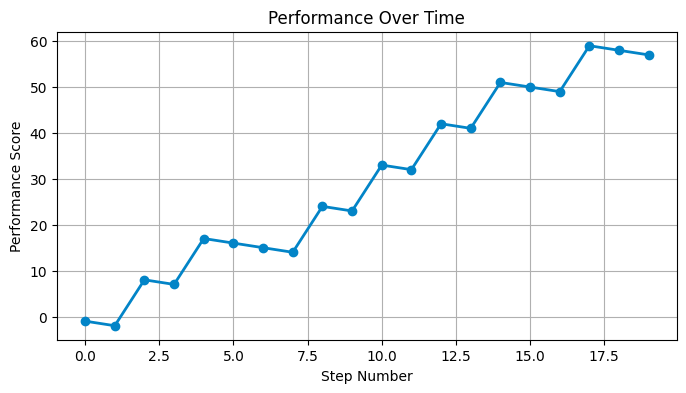

In [1]:
import random
import time
import matplotlib.pyplot as plt

# STEP 1: Define Dynamic Environment Class
class Environment:
    def __init__(self):
        self.rooms = {
            "A": random.choice(["Clean", "Dirty"]),
            "B": random.choice(["Clean", "Dirty"]),
            "C": random.choice(["Clean", "Dirty"]),
            "D": random.choice(["Clean", "Dirty"])
        }
        self.agent_location = random.choice(list(self.rooms.keys()))
        self.score = 0

    def display(self):
        print("\nEnvironment State:")
        print(f"  A: {self.rooms['A']} | B: {self.rooms['B']}")
        print(f"  C: {self.rooms['C']} | D: {self.rooms['D']}")
        print(f"  Agent is at: {self.agent_location}")
        print(f"  Current Score: {self.score}")
        print("-" * 50)

    def regenerate_dirt(self, probability=0.2):
        for room in self.rooms:
            if self.rooms[room] == "Clean" and random.random() < probability:
                self.rooms[room] = "Dirty"
                print(f"  [Dynamic Event] Room {room} became dirty again!")


# STEP 2: Define Rational Vacuum Cleaner Agent
class VacuumAgent:
    def __init__(self, environment):
        self.env = environment
        self.performance_log = []

    def perceive_and_act(self):
        location = self.env.agent_location
        status = self.env.rooms[location]

        if status == "Dirty":
            print(f"Cleaning room {location}...")
            self.env.rooms[location] = "Clean"
            self.env.score += 10
        else:
            next_room = random.choice(list(self.env.rooms.keys()))
            while next_room == location:
                next_room = random.choice(list(self.env.rooms.keys()))
            print(f"Moving from {location} -> {next_room}")
            self.env.agent_location = next_room
            self.env.score -= 1

        self.performance_log.append(self.env.score)


# STEP 3: Simulation Function
def run_simulation(steps=20):
    random.seed(42)
    env = Environment()
    agent = VacuumAgent(env)

    print("Initial Environment:")
    env.display()

    for step in range(steps):
        print(f"\nStep {step + 1}/{steps}")
        agent.perceive_and_act()
        env.regenerate_dirt(probability=0.2)
        env.display()

    print("\nSimulation Complete!")
    print(f"Final Room States: {env.rooms}")
    print(f"Final Score: {env.score}")

    plt.figure(figsize=(8, 4))
    plt.plot(agent.performance_log, marker='o', color='#0284C7', linewidth=2)
    plt.title("Performance Over Time")
    plt.xlabel("Step Number")
    plt.ylabel("Performance Score")
    plt.grid(True)
    plt.show()


run_simulation(steps=20)